# Reference solution: hidden drivers of defects

This notebook solves the task the way a careful analyst would, using only `data/`.
It follows the three EDA steps from the task definition:

1. **Describe** the data (DDA): structure, quality issues, cleaning, A1-A4.
2. **Identify salient features**: leakage, regime change, direct drivers, B1-B3.
3. **Interpret salient features**: the supplier switch, the humidity optimum for Alpha resin and the cleaning counterfactual, C1-C3.

It produces `reference_answer.json` in the answer format of the task, then (section 4 only) checks it against the answer key.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

DATA = Path("../data")
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})
pd.set_option("display.width", 140)

raw = pd.read_csv(DATA / "batches.csv")
suppliers = pd.read_csv(DATA / "suppliers.csv")
maintenance = pd.read_csv(DATA / "maintenance.csv", parse_dates=["date"])
print(raw.shape, suppliers.shape, maintenance.shape)
raw.head()

(3060, 15) (3, 5) (76, 4)


,batch_id,production_date,line,shift,operator_id,supplier_code,machine_age_years,ambient_temp_c,mold_temp,humidity_pct,cycle_time_s,units_produced,defective_units,qc_inspection_min,rework_cost_eur
0,B-670945,2025-01-06,L1,Night,OP-01,SP-01,3.7,15.8,214.8,28.6,30.1,586,23,20.9,82.77
1,B-654357,2025-01-06,L1,N,OP-04,sp-01,6.9,14.6,206.1,27.6,31.1,354,10,20.9,36.44
2,B-299201,2025-01-06,L1,D,OP-06,SP-02,5.1,14.9,208.8,18.0,30.1,385,19,23.6,84.86
3,B-181224,2025-01-06,L1,Night,OP-02,SP-01,6.0,15.1,207.5,46.7,28.1,532,30,22.1,119.67
4,B-854898,2025-01-06,L2,Day,OP-12,SP-01,5.6,18.2,205.7,42.5,28.0,813,28,22.5,115.56


## 1. Describe the data

### 1.1 Structure and summary statistics

In [2]:
raw.dtypes.to_frame('dtype').T

,batch_id,production_date,line,shift,operator_id,supplier_code,machine_age_years,ambient_temp_c,mold_temp,humidity_pct,cycle_time_s,units_produced,defective_units,qc_inspection_min,rework_cost_eur
dtype,str,str,str,str,str,str,float64,float64,float64,float64,float64,int64,int64,float64,float64


In [3]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
machine_age_years,3060.0,7.19,4.69,1.00,4.2,5.40,7.40,21.50
ambient_temp_c,3060.0,21.94,4.62,10.40,17.6,23.10,25.90,30.60
mold_temp,3060.0,257.28,91.52,0.00,208.4,216.10,231.30,453.90
humidity_pct,3004.0,31.05,14.87,-1.00,21.3,30.10,41.40,72.30
cycle_time_s,3060.0,30.14,4.07,18.00,27.4,30.10,32.90,44.70
units_produced,3060.0,572.48,296.41,93.00,360.0,526.00,720.00,3387.00
defective_units,3060.0,34.23,28.44,2.00,17.0,26.00,43.00,380.00
qc_inspection_min,3060.0,22.76,3.00,14.30,20.8,22.40,24.30,48.40
rework_cost_eur,3060.0,144.03,121.10,8.24,68.5,109.02,180.12,1486.82


Two values stand out in `describe()` before any plotting:

- `humidity_pct` has a minimum of **-1**, which is impossible for relative humidity, so it is a sentinel for a missing reading.
- `mold_temp` has a minimum of **0** and a maximum above 400, both implausible for one unit of measurement.

### 1.2 Categorical columns

In [4]:
for col in ["line", "shift", "supplier_code"]:
    print(col, raw[col].map(repr).value_counts().to_dict(), "\n")

line {"'L1'": 873, "'L2'": 819, "'L3'": 746, "'L4'": 622} 

shift {"'Day'": 1460, "'Night'": 996, "'DAY'": 89, "'D'": 88, "' Day'": 86, "'day'": 86, "'NIGHT'": 72, "'night'": 65, "'Night '": 60, "'N'": 58} 

supplier_code {"'SP-01'": 1254, "'SP-03'": 666, "'SP-02'": 651, "' Sp-01'": 92, "'SP-01 '": 80, "'sp-01'": 67, "'SP-03 '": 54, "' Sp-02'": 51, "'sp-03'": 39, "' Sp-03'": 37, "'sp-02'": 36, "'SP-02 '": 33} 



`shift` has spelling variants of two values (`Day`, `day`, `D`, `' Day'`, ...), and `supplier_code` has case and whitespace variants of the three codes in `suppliers.csv`. A join on the raw key would silently drop rows.

### 1.3 Duplicates

In [5]:
print("exact duplicate rows:", raw.duplicated().sum())
print("repeated batch_id:   ", raw["batch_id"].duplicated().sum())
dup_ids = raw.loc[raw["batch_id"].duplicated(), "batch_id"]
print("rows sharing a repeated id that are NOT exact copies:",
      (raw[raw["batch_id"].isin(dup_ids)].drop_duplicates()["batch_id"].duplicated()).sum())

exact duplicate rows: 60
repeated batch_id:    60
rows sharing a repeated id that are NOT exact copies: 0


Every repeated `batch_id` is an exact copy of another row (a double export), so dropping exact duplicates is safe and loses no information.

### 1.4 Mold temperature units

In [6]:
valid = raw[raw["mold_temp"] > 0]
print(valid.groupby("line")["mold_temp"].describe().round(1))
print("\nzeros per line:", raw[raw["mold_temp"] == 0].groupby("line").size().to_dict())

      count   mean   std    min    25%    50%    75%    max
line                                                       
L1    852.0  215.8   9.2  191.3  208.8  216.7  223.0  238.1
L2    809.0  211.0   7.0  189.3  206.4  211.0  216.1  232.2
L3    737.0  411.8  12.2  376.9  403.5  412.0  419.7  453.9
L4    613.0  210.8   7.0  184.8  206.1  210.9  215.6  232.3

zeros per line: {'L1': 21, 'L2': 10, 'L3': 9, 'L4': 9}


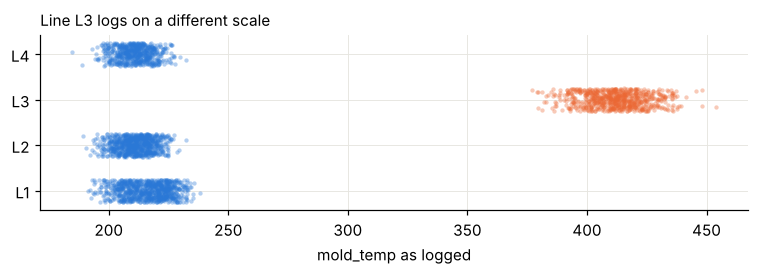

In [7]:
fig, ax = plt.subplots(figsize=(7, 2.6))
for i, (line, g) in enumerate(valid.groupby("line")):
    ax.scatter(g["mold_temp"], np.full(len(g), i) + np.random.default_rng(0).uniform(-0.25, 0.25, len(g)),
               s=8, color=ORANGE if line == "L3" else BLUE, alpha=0.35, linewidths=0)
ax.set_yticks(range(4), sorted(valid["line"].unique()))
ax.set_xlabel("mold_temp as logged")
ax.set_title("Line L3 logs on a different scale", loc="left", fontsize=10)
plt.tight_layout()

L3 sits around 410 while the other lines sit around 210. (410 - 32) × 5/9 ≈ 210, so **L3 logs in °F**. The zeros appear on every line and are sensor failures, not cold molds.

### 1.5 The other two files

In [8]:
print(suppliers.to_string(index=False), "\n")
print(maintenance["event"].value_counts().to_string(), "\n")
maintenance[maintenance["event"] != "mold_cleaning"]

supplier_code supplier_name resin_grade country pre_dried
        SP-01         Alpha     PP-H350      DE        no
        SP-02          Beta     PP-H350      PL       yes
        SP-03         Gamma     PP-H420      CZ       yes 

event
mold_cleaning         74
sensor_replacement     1
calibration_check      1 



,date,line,event,note
33,2025-04-14,L1,sensor_replacement,Mold temperature sensor replaced.
72,2025-09-22,L1,calibration_check,Mold temperature sensor reads 8.0 degC above t...


Two facts that the batch table alone does not show:

- **Alpha resin is not pre-dried** (`pre_dried = no`). Undried resin absorbs moisture, so its response to hall humidity may differ from the other two. Section 3.2 tests this.
- **L1's mold temperature sensor was replaced on 2025-04-14**, and a later calibration check found that it **reads 8.0 °C high**. Readings from the new sensor are biased, not invalid. The check below confirms the bias in the data before correcting it.

gap before: 0.1 °C | after: 8.0 °C


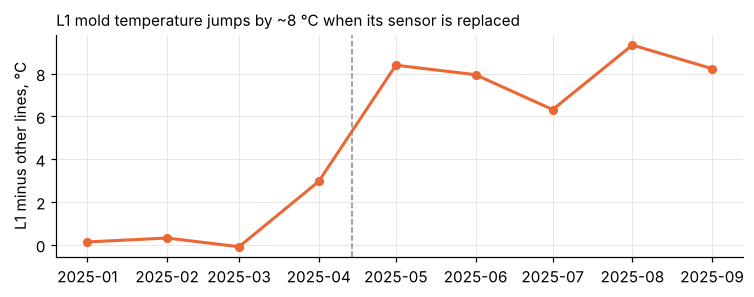

In [9]:
mt = raw[raw["mold_temp"] > 0].assign(month=lambda d: pd.to_datetime(d["production_date"]).dt.to_period("M"))
mt.loc[mt["line"] == "L3", "mold_temp"] = (mt.loc[mt["line"] == "L3", "mold_temp"] - 32) * 5 / 9
monthly = mt.groupby(["month", "line"])["mold_temp"].mean().unstack()
gap = monthly["L1"] - monthly.drop(columns="L1").mean(axis=1)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(gap.index.to_timestamp(), gap.values, color=ORANGE, lw=2, marker="o", ms=5)
ax.axvline(pd.Timestamp("2025-04-14"), color=GRAY, lw=1, ls="--")
ax.set_ylabel("L1 minus other lines, °C")
ax.set_title("L1 mold temperature jumps by ~8 °C when its sensor is replaced", loc="left", fontsize=10)
plt.tight_layout()
print("gap before:", round(gap[:"2025-03"].mean(), 1), "°C | after:", round(gap["2025-05":].mean(), 1), "°C")

The jump is a step of about 8 °C on L1 only, at the replacement date, while the hall temperature does not move that way. L1's defect rate does not follow the step either (section 2.4 would otherwise show it as a process effect). So the correction is: **subtract 8.0 °C from L1 readings from 2025-04-14 on.**

**Cleaning intervals.** The log also records when each line's molds were cleaned. The interval between cleanings is a candidate driver that is not a column of `batches.csv`.

In [10]:
cl = maintenance[maintenance["event"] == "mold_cleaning"].sort_values(["line", "date"]).copy()
cl["interval_days"] = cl.groupby("line")["date"].diff().dt.days
cl.groupby(cl["date"].dt.month)["interval_days"].mean().round(1).to_frame("mean interval, days").T

date,1,2,3,4,5,6,7,8,9,12
"mean interval, days",14.0,12.7,12.1,13.5,13.2,11.7,18.2,30.3,23.1,NaN


Cleanings normally happen every 10-16 days, but in July and August the interval roughly doubles (holidays), and the long gaps reach into early September. For each batch, **days since its line's last cleaning** comes from a backward as-of join: the last cleaning on or before the production date, because cleanings happen before the first shift.

### 1.6 Cleaning

In [11]:
def clean(raw: pd.DataFrame, suppliers: pd.DataFrame, maintenance: pd.DataFrame) -> pd.DataFrame:
    df = raw.drop_duplicates().copy()
    df["shift"] = df["shift"].str.strip().str[0].str.upper().map({"D": "Day", "N": "Night"})
    df["supplier_code"] = df["supplier_code"].str.strip().str.upper()
    df = df.merge(suppliers, on="supplier_code", how="left", validate="many_to_one")
    df["humidity_pct"] = df["humidity_pct"].where(df["humidity_pct"] >= 0)   # -1 -> NaN
    df["mold_temp"] = df["mold_temp"].where(df["mold_temp"] > 0)             # 0 -> NaN
    is_f = df["line"] == "L3"
    df.loc[is_f, "mold_temp"] = (df.loc[is_f, "mold_temp"] - 32) * 5 / 9   # degF -> degC
    df["production_date"] = pd.to_datetime(df["production_date"])
    drift = (df["line"] == "L1") & (df["production_date"] >= "2025-04-14")
    df.loc[drift, "mold_temp"] -= 8.0                                         # biased L1 sensor
    cleanings = (maintenance.loc[maintenance["event"] == "mold_cleaning", ["line", "date"]]
                 .rename(columns={"date": "cleaned_on"}).sort_values("cleaned_on"))
    df = pd.merge_asof(df.sort_values("production_date"), cleanings, left_on="production_date",
                       right_on="cleaned_on", by="line", direction="backward")
    df["days_since_cleaning"] = (df["production_date"] - df["cleaned_on"]).dt.days
    df["rate"] = df["defective_units"] / df["units_produced"]
    return df.drop(columns="cleaned_on").sort_values("batch_id").reset_index(drop=True)

df = clean(raw, suppliers, maintenance)
assert df["days_since_cleaning"].notna().all()
assert df["shift"].notna().all() and df["supplier_name"].notna().all()
assert df.groupby("line")["mold_temp"].median().between(195, 225).all()
print(df.shape)
df[["shift", "supplier_name"]].value_counts().unstack()

(3000, 21)


supplier_name,Alpha,Gamma,Beta
shift,,,
Day,852,460,460
Night,616,317,295


### 1.7 Answers A1-A4

In [12]:
answers = {}
answers["A1_unique_batches"] = int(df["batch_id"].nunique())
answers["A2_missing_humidity_batches"] = int(df["humidity_pct"].isna().sum())
answers["A3_overall_defect_rate"] = round(float(df["defective_units"].sum() / df["units_produced"].sum()), 5)
answers["A4_median_mold_temp_c"] = round(float(df["mold_temp"].median()), 2)

print("mean of batch rates (not the overall rate):", round(df["rate"].mean(), 5))
print("missing humidity, NaN only (sentinels ignored):", raw.drop_duplicates()["humidity_pct"].isna().sum())
print("median mold temperature without the L1 sensor correction:",
      round(float(df["mold_temp"].where(~((df["line"] == "L1") & (df["production_date"] >= "2025-04-14")),
                                        df["mold_temp"] + 8.0).median()), 2))
answers

mean of batch rates (not the overall rate): 0.06388
missing humidity, NaN only (sentinels ignored): 55
median mold temperature without the L1 sensor correction: 211.9


{'A1_unique_batches': 3000,
 'A2_missing_humidity_batches': 226,
 'A3_overall_defect_rate': 0.05978,
 'A4_median_mold_temp_c': 210.9}

The overall defect rate is the share of *all produced units* that were defective, so it is a pooled ratio. The mean of batch rates differs because the worst line also makes the smallest batches, which gives each of its few units too much weight.

## 2. Identify salient features

### 2.1 Leakage: columns determined by the outcome

In [13]:
num = df.select_dtypes("number").drop(columns=["rate"])
num.corrwith(df["defective_units"]).sort_values(ascending=False).round(3).to_frame("r with defective_units")

,r with defective_units
defective_units,1.000
rework_cost_eur,0.989
qc_inspection_min,0.748
units_produced,0.535
mold_temp,0.325
days_since_cleaning,0.275
ambient_temp_c,0.236
humidity_pct,0.032
machine_age_years,-0.132
cycle_time_s,-0.192


In [14]:
ratio = df["rework_cost_eur"] / df["defective_units"].replace(0, np.nan)
print("rework cost per defective part: median", round(ratio.median(), 2), "IQR", ratio.quantile([.25, .75]).round(2).tolist())
slope = np.polyfit(df["defective_units"], df["qc_inspection_min"], 1)
print(f"qc minutes = {slope[1]:.1f} + {slope[0]:.3f} x defective_units")

rework cost per defective part: median 4.19 IQR [3.92, 4.47]
qc minutes = 20.0 + 0.079 x defective_units


`rework_cost_eur` is almost exactly 4.2 € per defective part, and `qc_inspection_min` grows with the number of defects found. Both are **recorded after quality control and computed from the outcome**. They are excellent "predictors" only because they encode Y, so they must be excluded from any driver analysis (B2).

### 2.2 Univariate view: what a correlation matrix would suggest

In [15]:
cands = ["mold_temp", "humidity_pct", "cycle_time_s", "machine_age_years", "ambient_temp_c", "days_since_cleaning"]
df[cands].corrwith(df["rate"]).round(3).to_frame("Pearson r with defect rate")

,Pearson r with defect rate
mold_temp,0.368
humidity_pct,-0.008
cycle_time_s,-0.246
machine_age_years,0.355
ambient_temp_c,0.276
days_since_cleaning,0.301


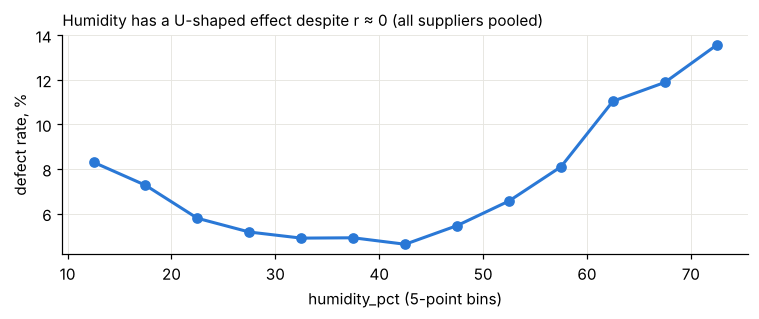

In [16]:
bins = pd.cut(df["humidity_pct"], np.arange(10, 81, 5))
by_hum = df.groupby(bins, observed=True).apply(lambda g: g["defective_units"].sum() / g["units_produced"].sum())
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot([b.mid for b in by_hum.index], by_hum.values * 100, color=BLUE, lw=2, marker="o", ms=6)
ax.set_xlabel("humidity_pct (5-point bins)"); ax.set_ylabel("defect rate, %")
ax.set_title("Humidity has a U-shaped effect despite r ≈ 0 (all suppliers pooled)", loc="left", fontsize=10)
plt.tight_layout()

Pearson r for humidity is close to 0, yet the binned rate is clearly U-shaped. Linear correlation cannot see a symmetric non-linear effect. `machine_age_years` and `ambient_temp_c`, on the other hand, correlate with the rate. Section 2.4 tests whether those correlations are direct effects or confounding.

### 2.3 Regime change over time

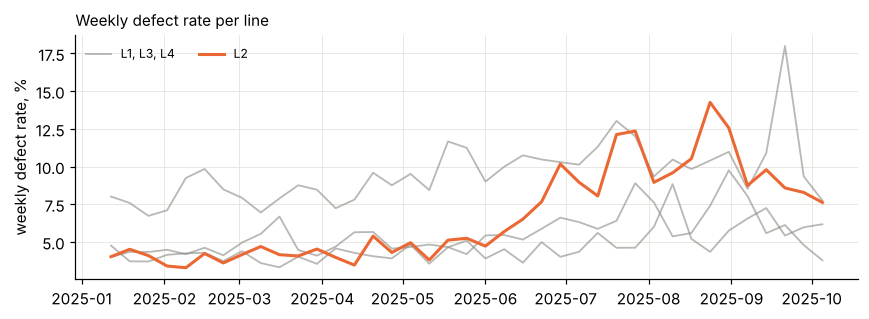

In [17]:
weekly = (df.set_index("production_date").groupby("line")[["defective_units", "units_produced"]]
          .resample("W").sum())
weekly = (weekly["defective_units"] / weekly["units_produced"]).unstack(0)
fig, ax = plt.subplots(figsize=(8, 3))
others = [l for l in weekly if l != "L2"]
for k, line in enumerate(others):
    ax.plot(weekly.index, weekly[line] * 100, lw=1.2, color=GRAY, alpha=0.6,
            label=", ".join(others) if k == 0 else None)
ax.plot(weekly.index, weekly["L2"] * 100, lw=2, color=ORANGE, label="L2")
ax.legend(ncol=2, frameon=False, fontsize=8); ax.set_ylabel("weekly defect rate, %")
ax.set_title("Weekly defect rate per line", loc="left", fontsize=10)
plt.tight_layout()

All lines drift up in summer (hotter hall, hotter molds, and longer gaps between mold cleanings), so a changepoint search on raw rates would be confounded by season. The search below therefore runs on **observed / expected** defects, where *expected* comes from a model of the process variables, including days since cleaning, without any time term. For each line it finds the single split date that maximizes the Poisson log-likelihood ratio.

In [18]:
HUMIDITY = "C(supplier_name):humidity_pct + C(supplier_name):I(humidity_pct**2)"
base_formula = (f"rate ~ C(line) + C(supplier_name) + C(shift) + mold_temp + {HUMIDITY}"
                " + cycle_time_s + days_since_cleaning")
model_df = df.dropna(subset=["mold_temp", "humidity_pct"]).copy()
base = smf.glm(base_formula, model_df, family=sm.families.Binomial(),
               var_weights=model_df["units_produced"]).fit(scale="X2")
model_df["expected"] = base.predict(model_df) * model_df["units_produced"]

def best_split(g: pd.DataFrame, margin_days: int = 14):
    daily = g.groupby("production_date")[["defective_units", "expected"]].sum().sort_index()
    o, e = daily["defective_units"].to_numpy(), daily["expected"].to_numpy()
    co, ce = o.cumsum(), e.cumsum()
    def seg(oo, ee): return oo * np.log(oo / ee)
    total = seg(co[-1], ce[-1])
    llr = [seg(co[i - 1], ce[i - 1]) + seg(co[-1] - co[i - 1], ce[-1] - ce[i - 1]) - total
           for i in range(margin_days, len(o) - margin_days)]
    i = int(np.argmax(llr)) + margin_days
    return daily.index[i].date(), float(max(llr)), co[i - 1] / ce[i - 1], (co[-1] - co[i - 1]) / (ce[-1] - ce[i - 1])

splits = pd.DataFrame([(l, *best_split(g)) for l, g in model_df.groupby("line")],
                      columns=["line", "split_date", "LLR", "O/E before", "O/E after"]).set_index("line")
splits.round(3)

,split_date,LLR,O/E before,O/E after
line,,,,
L1,2025-02-12,20.965,1.126,0.986
L2,2025-06-16,1203.854,0.751,1.313
L3,2025-07-12,7.255,1.019,0.968
L4,2025-06-30,9.467,1.027,0.953


Only L2 shows a large likelihood ratio: its observed/expected defect ratio jumps by a large factor at one date. The other lines' best splits are noise of much smaller magnitude.

In [19]:
regime_line = splits["LLR"].idxmax()
regime_date = splits.loc[regime_line, "split_date"]
df["regime"] = ((df["line"] == regime_line) & (df["production_date"] >= pd.Timestamp(regime_date))).astype(int)
answers["B3_regime_change"] = {"line": regime_line, "date": str(regime_date)}
answers["B3_regime_change"]

{'line': 'L2', 'date': '2025-06-16'}

### 2.4 Direct drivers: one multivariable model

Each batch is one observation of a noisy process. Besides binomial sampling noise, batches differ by an unobserved batch-level factor, so a large batch is *not* proportionally more informative than a small one. The model is therefore an OLS on the **empirical logit** of each batch, `log((d + 0.5) / (n - d + 0.5))`, with heteroskedasticity-robust (HC3) standard errors. It contains every candidate variable plus the controls (line, supplier, regime, days since cleaning) and a humidity curve per supplier (section 3.2 shows why). A variable with a *direct* effect keeps a clear signal when everything else is held fixed, while a confounded one loses it.

In [20]:
model_df = df.dropna(subset=["mold_temp", "humidity_pct"]).copy()
model_df["y"] = np.log((model_df["defective_units"] + 0.5) / (model_df["units_produced"] - model_df["defective_units"] + 0.5))
full_formula = (f"y ~ C(line) + C(supplier_name) + C(shift) + mold_temp + {HUMIDITY}"
                " + cycle_time_s + machine_age_years + ambient_temp_c + regime + days_since_cleaning")
full = smf.ols(full_formula, model_df).fit(cov_type="HC3")
print(full.summary().tables[1])

                                                   coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------
Intercept                                       -7.3698      0.217    -33.888      0.000      -7.796      -6.944
C(line)[T.L2]                                    0.0655      0.020      3.205      0.001       0.025       0.106
C(line)[T.L3]                                    0.2039      0.017     12.014      0.000       0.171       0.237
C(line)[T.L4]                                    0.9274      0.047     19.642      0.000       0.835       1.020
C(supplier_name)[T.Beta]                         0.7927      0.102      7.787      0.000       0.593       0.992
C(supplier_name)[T.Gamma]                        1.0037      0.098     10.230      0.000       0.811       1.196
C(shift)[T.Night]                                0.1642      0.013     12.877      0.000       0

In [21]:
op_model = smf.ols(full_formula.replace("C(line)", "C(operator_id)"), model_df).fit()
tests = {
    "mold_temp": full.pvalues["mold_temp"],
    "humidity_pct (all curve terms)": float(full.f_test(
        ", ".join(f"{k} = 0" for k in full.params.index if "humidity_pct" in k)).pvalue),
    "cycle_time_s": full.pvalues["cycle_time_s"],
    "shift": full.pvalues["C(shift)[T.Night]"],
    "machine_age_years": full.pvalues["machine_age_years"],
    "ambient_temp_c": full.pvalues["ambient_temp_c"],
    # operator_id is nested in line: does replacing line dummies by operator dummies add anything?
    "operator_id (within line)": op_model.compare_f_test(smf.ols(full_formula, model_df).fit())[1],
}
pd.Series(tests, name="p-value").map(lambda p: f"{p:.2e}").to_frame()

,p-value
mold_temp,4.80e-177
humidity_pct (all curve terms),0.00e+00
cycle_time_s,7.37e-159
shift,6.05e-38
machine_age_years,9.43e-01
ambient_temp_c,7.98e-01
operator_id (within line),6.76e-01


Mold temperature, humidity, cycle time and shift are overwhelmingly significant (p < 0.001). Machine age, ambient temperature and operator add nothing once line and mold temperature are in the model:

- **Machine age** correlates with defects only because the oldest presses are on L4, the worst line.
- **Ambient temperature** acts *through* mold temperature (a hot hall heats the molds), and the hot months are also the months with long cleaning gaps. With both in the model it has no effect of its own.
- **Operators** are tied to lines, and their apparent differences are line differences.

Leaving out the maintenance log turns ambient temperature into a false driver:

In [22]:
no_log = smf.ols(full_formula.replace(" + days_since_cleaning", ""), model_df).fit(cov_type="HC3")
print(f"ambient_temp_c without days since cleaning: p = {no_log.pvalues['ambient_temp_c']:.1e}")
print(f"ambient_temp_c with days since cleaning:    p = {full.pvalues['ambient_temp_c']:.2f}")
print(f"days_since_cleaning: +{full.params['days_since_cleaning']:.4f} logit per day, p = {full.pvalues['days_since_cleaning']:.1e}")

ambient_temp_c without days since cleaning: p = 8.4e-05
ambient_temp_c with days since cleaning:    p = 0.80
days_since_cleaning: +0.0204 logit per day, p = 2.0e-109


#### Side note: a tempting model that gets this wrong

A binomial GLM weighted by batch size looks like the textbook choice for defect counts. It assumes that a batch of 1,000 parts carries twice the information of a batch of 500. With batch-level variation that is false, the standard errors shrink too much, and null effects start to look significant:

In [23]:
glm_df = model_df.assign(rate=model_df["defective_units"] / model_df["units_produced"])
glm = lambda f: smf.glm(f.replace("y ~", "rate ~"), glm_df, family=sm.families.Binomial(),
                        var_weights=glm_df["units_produced"]).fit(scale="X2")
g_full, g_op = glm(full_formula), glm(full_formula.replace("C(line)", "C(operator_id)"))
from scipy import stats
F = (g_full.deviance - g_op.deviance) / (g_full.df_resid - g_op.df_resid) / g_op.scale
print("weighted quasi-binomial GLM, operator within line: p =",
      f"{stats.f.sf(F, g_full.df_resid - g_op.df_resid, g_op.df_resid):.1e}")
print("weighted quasi-binomial GLM, machine age:          p =", f"{g_full.pvalues['machine_age_years']:.1e}")

weighted quasi-binomial GLM, operator within line: p = 1.8e-02
weighted quasi-binomial GLM, machine age:          p = 1.1e-01


With this seed the weighted GLM declares the operator effect significant at p < 0.001, even though the operators have no effect by construction. Across 20 seeds the empirical-logit OLS recovered exactly the true driver set every time (`tests/test_reference.py`). This is a statistical trap that comes from the noise structure, which is realistic for production data.

In [24]:
name_map = {"mold_temp": "mold_temp", "humidity_pct (all curve terms)": "humidity_pct",
            "cycle_time_s": "cycle_time_s", "shift": "shift", "machine_age_years": "machine_age_years",
            "ambient_temp_c": "ambient_temp_c", "operator_id (within line)": "operator_id"}
answers["B1_direct_drivers"] = sorted(name_map[k] for k, p in tests.items() if p < 0.001)
answers["B2_leakage_columns"] = ["qc_inspection_min", "rework_cost_eur"]
answers["B1_direct_drivers"], answers["B2_leakage_columns"]

(['cycle_time_s', 'humidity_pct', 'mold_temp', 'shift'],
 ['qc_inspection_min', 'rework_cost_eur'])

## 3. Interpret salient features

### 3.1 Which single supplier would be best? (Simpson's paradox)

In [25]:
pooled = lambda g: g["defective_units"].sum() / g["units_produced"].sum()
overall = df.groupby("supplier_name").apply(pooled).rename("overall")
within = df.groupby(["line", "supplier_name"]).apply(pooled).unstack()
alloc = pd.crosstab(df["line"], df["supplier_name"], normalize="columns").round(2)
print("Defect rate overall:\n", (overall * 100).round(2).to_string(), "\n")
print("Defect rate within each line (%):\n", (within * 100).round(2), "\n")
print("Where each supplier's batches go (share of supplier's batches):\n", alloc)

Defect rate overall:
 supplier_name
Alpha    5.73
Beta     6.63
Gamma    6.01 

Defect rate within each line (%):
 supplier_name  Alpha  Beta  Gamma
line                             
L1              4.72  3.90   4.99
L2              6.57  5.74   6.80
L3              5.70  4.93   5.69
L4             10.62  9.34  10.22 

Where each supplier's batches go (share of supplier's batches):
 supplier_name  Alpha  Beta  Gamma
line                             
L1              0.36  0.12   0.30
L2              0.34  0.11   0.29
L3              0.26  0.15   0.31
L4              0.04  0.63   0.10


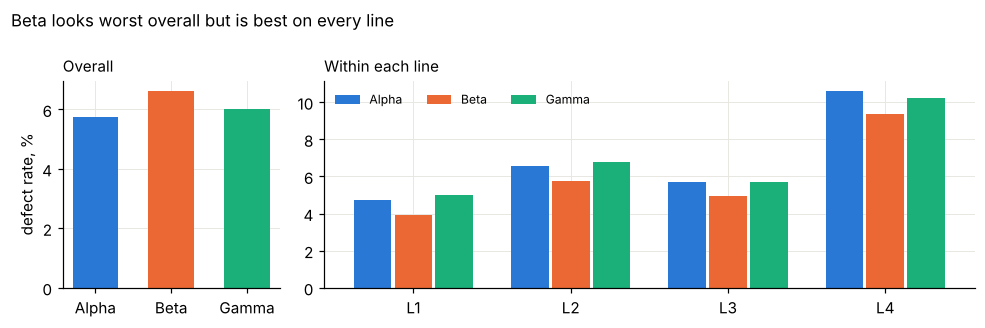

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), gridspec_kw={"width_ratios": [1, 3]})
colors = {"Alpha": BLUE, "Beta": ORANGE, "Gamma": AQUA}
axes[0].bar(overall.index, overall * 100, color=[colors[s] for s in overall.index], width=0.6)
axes[0].set_title("Overall", loc="left", fontsize=10); axes[0].set_ylabel("defect rate, %")
w = 0.26
for k, s in enumerate(within.columns):
    axes[1].bar(np.arange(4) + (k - 1) * w, within[s] * 100, width=w - 0.02, color=colors[s], label=s)
axes[1].set_xticks(range(4), within.index); axes[1].legend(frameon=False, fontsize=8, ncol=3)
axes[1].set_title("Within each line", loc="left", fontsize=10)
fig.suptitle("Beta looks worst overall but is best on every line", x=0.01, ha="left", fontsize=11)
plt.tight_layout()

Because the humidity response differs by supplier (section 3.2), a supplier's advantage depends on the humidity, so a single coefficient cannot answer the question. The question is a plant-wide switch, so the model answers it directly: predict every batch as if it had used one supplier, keep everything else as it was, and compare the expected overall defect rates.

In [27]:
def expected_rate(model, data, **changes):
    p = 1 / (1 + np.exp(-model.predict(data.assign(**changes))))
    return float((p * data["units_produced"]).sum() / data["units_produced"].sum())

now = expected_rate(full, model_df)
switch = pd.Series({s: expected_rate(full, model_df, supplier_name=s) for s in ["Alpha", "Beta", "Gamma"]})
print((switch / now).round(3).rename("expected defects vs today").to_string())
answers["C1_best_supplier"] = str(switch.idxmin())
answers["C1_best_supplier"]

Alpha    1.047
Beta     0.898
Gamma    1.027


'Beta'

**Beta looks worst overall but is best within every line.** About 75 % of Beta's batches go to L4, the oldest line with the highest defect rate, while Alpha mostly supplies the better lines. The aggregate comparison mixes up "which supplier" with "which line". If Beta supplied every batch, the plant would expect about 10 % fewer defects than today, so switching away from it on the evidence of the overall average would be a costly mistake.

### 3.2 Humidity optimum for Alpha resin

In [28]:
pooled_formula = full_formula.replace(HUMIDITY, "humidity_pct + I(humidity_pct**2)")
pooled_fit = smf.ols(pooled_formula, model_df).fit(cov_type="HC3")
same_curve = smf.ols(pooled_formula, model_df).fit()
print("one curve for all suppliers, optimum:",
      round(-pooled_fit.params["humidity_pct"] / (2 * pooled_fit.params["I(humidity_pct ** 2)"]), 1), "%")
print("does the curve differ by supplier? F-test p =", f"{smf.ols(full_formula, model_df).fit().compare_f_test(same_curve)[1]:.1e}")

def optimum(params, s):
    return -params[f"C(supplier_name)[{s}]:humidity_pct"] / (2 * params[f"C(supplier_name)[{s}]:I(humidity_pct ** 2)"])

print({s: round(optimum(full.params, s), 1) for s in ["Alpha", "Beta", "Gamma"]})

one curve for all suppliers, optimum: 36.8 %


does the curve differ by supplier? F-test p = 4.6e-183
{'Alpha': np.float64(29.9), 'Beta': np.float64(42.3), 'Gamma': np.float64(43.9)}


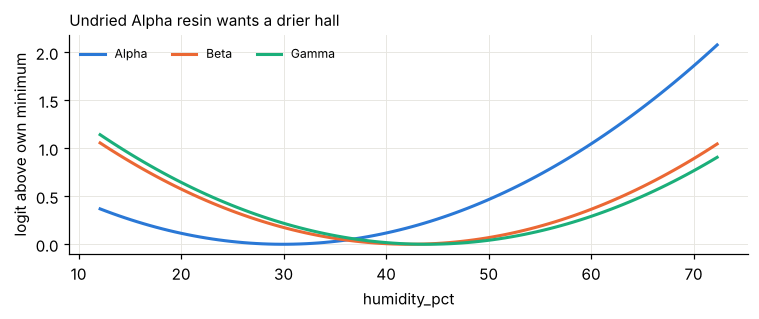

In [29]:
grid = np.linspace(model_df["humidity_pct"].min(), model_df["humidity_pct"].max(), 100)
fig, ax = plt.subplots(figsize=(7, 3))
for s in ["Alpha", "Beta", "Gamma"]:
    b = full.params
    curve = b[f"C(supplier_name)[{s}]:humidity_pct"] * grid + b[f"C(supplier_name)[{s}]:I(humidity_pct ** 2)"] * grid**2
    ax.plot(grid, curve - curve.min(), color=colors[s], lw=2, label=s)
ax.set_xlabel("humidity_pct"); ax.set_ylabel("logit above own minimum")
ax.legend(frameon=False, fontsize=8, ncol=3)
ax.set_title("Undried Alpha resin wants a drier hall", loc="left", fontsize=10)
plt.tight_layout()

In [30]:
rng = np.random.default_rng(0)
boot = []
for _ in range(200):
    s = model_df.sample(len(model_df), replace=True, random_state=rng.integers(1 << 31))
    boot.append(optimum(smf.ols(full_formula, s).fit().params, "Alpha"))
lo, hi = np.percentile(boot, [2.5, 97.5])
h_star = optimum(full.params, "Alpha")
answers["C2_optimal_humidity_pct"] = round(float(h_star), 1)
print(f"Alpha humidity optimum: {h_star:.1f} %  (bootstrap 95% CI {lo:.1f}-{hi:.1f})")

Alpha humidity optimum: 29.9 %  (bootstrap 95% CI 29.2-30.5)


The humidity curve clearly differs by supplier. Undried Alpha resin has its lowest defect rate in a much drier hall than the pre-dried resins, and a single curve fitted to all batches lands between the two. Once the plant runs on Alpha only, the humidity setpoint should follow Alpha's own curve, not the pooled one.

### 3.3 What would regular mold cleaning have saved?

In [31]:
plan = model_df["days_since_cleaning"] % 14   # an extra cleaning whenever 14 days have passed
ratio = expected_rate(full, model_df, days_since_cleaning=plan) / expected_rate(full, model_df)
observed = answers["A3_overall_defect_rate"]
rest = df[~df["production_date"].dt.month.isin([7, 8])]
naive = rest["defective_units"].sum() / rest["units_produced"].sum()
answers["C3_rate_with_regular_cleaning"] = round(float(observed * ratio), 5)
print(f"expected change in defects: {100 * (ratio - 1):.1f} %")
print(f"observed rate {observed:.5f} -> with regular cleaning {observed * ratio:.5f}")
print(f"(naive: the rate outside July and August, {naive:.5f}, also removes the hot-season and L2 effects)")

expected change in defects: -6.3 %
observed rate 0.05978 -> with regular cleaning 0.05603
(naive: the rate outside July and August, 0.05377, also removes the hot-season and L2 effects)


The model keeps every other condition of each batch as it was and only shortens the time since cleaning, so the answer isolates the cleaning effect. Comparing summer with the rest of the year would overstate it, because summer also brings hotter molds and falls after the L2 regime change.

## Answer

In [32]:
Path("reference_answer.json").write_text(json.dumps(answers, indent=2) + "\n")
print(json.dumps(answers, indent=2))

{
  "A1_unique_batches": 3000,
  "A2_missing_humidity_batches": 226,
  "A3_overall_defect_rate": 0.05978,
  "A4_median_mold_temp_c": 210.9,
  "B3_regime_change": {
    "line": "L2",
    "date": "2025-06-16"
  },
  "B1_direct_drivers": [
    "cycle_time_s",
    "humidity_pct",
    "mold_temp",
    "shift"
  ],
  "B2_leakage_columns": [
    "qc_inspection_min",
    "rework_cost_eur"
  ],
  "C1_best_supplier": "Beta",
  "C2_optimal_humidity_pct": 29.9,
  "C3_rate_with_regular_cleaning": 0.05603
}


## 4. Check against the answer key

*This section uses `eval/ground_truth.json`, which no model ever sees, and the benchmark's own scorer (`edabench.scorer`, defined in `docs/measure.md`).*

In [33]:
from edabench.scorer import score_text

gt = json.loads(Path("../eval/ground_truth.json").read_text())
result = score_text(json.dumps(answers), gt)
print("total:", result["total"], "| sections:", result["sections"])
pd.DataFrame(result["questions"]).set_index("qid")[["score", "weight", "answer", "truth"]]

total: 0.99568 | sections: {'describe': 0.999695, 'salient_features': 1.0, 'interpret': 0.988857}


,score,weight,answer,truth
qid,,,,
A1,1.000000,0.07,3000,3000
A2,1.000000,0.07,226,226
A3,0.998781,0.07,0.05978,0.059775
A4,1.000000,0.07,210.9,210.9
B1,1.000000,0.14,"[cycle_time_s, humidity_pct, mold_temp, shift]","[cycle_time_s, humidity_pct, mold_temp, shift]"
B2,1.000000,0.10,"[qc_inspection_min, rework_cost_eur]","[qc_inspection_min, rework_cost_eur]"
B3,1.000000,0.10,"{'line': 'L2', 'date': '2025-06-16'}","{'line': 'L2', 'date': '2025-06-16'}"
C1,1.000000,0.12,Beta,Beta
C2,0.985207,0.13,29.9,30.0
